# 07.1 · Time series: trend, seasonality, noise

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/01-time-series-basics/lesson.ipynb)

Read the [README](README.md) first. This notebook loads two years of ShopWave revenue, looks at it at three zoom levels, takes it apart into trend, seasonality and noise, and shows why the train/test splits from Module 04 do not work on time.

## 1. Two years of revenue

Both sheets of Online Retail II, joined without double-counting December 2010, cleaned with the usual `clean_retail()`. Three choices are made up front and you should know them:

- **Two one-off orders are removed** (80,995 paper birdies and 74,215 storage jars). Each was cancelled the same day; their cancellations are already gone, so the orders themselves would show as phantom £168k and £77k spikes.
- **The series stops on Sunday 4 December 2011.** The data ends on Friday 9 December, mid-week. A partial week or month at the end looks like a collapse in sales and would fool every model in this module.
- **Revenue here is from registered customers** (rows with a customer ID), as in every module so far. Guest checkouts add about a quarter more; the shape is the same.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


## 2. Three zoom levels: `resample`

`resample("D")`, `"W"` and `"ME"` group timestamps into days, weeks (ending Sunday) and months (labelled by month-end). It is `groupby` for time: the index must be a `DatetimeIndex`.

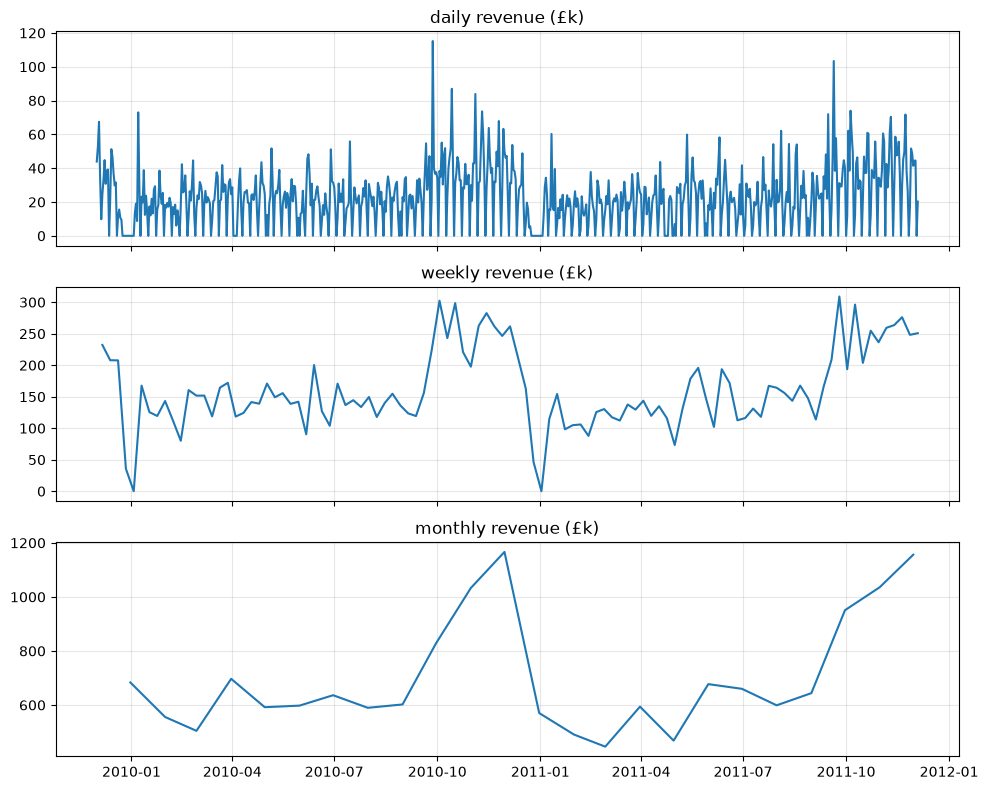

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, (name, s) in zip(axes, [("daily", daily), ("weekly", weekly), ("monthly", monthly)]):
    ax.plot(s.index, s.values / 1000)
    ax.set_title(f"{name} revenue (£k)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Daily is too noisy to read; you see weekly rhythm and the closed days at zero. Weekly shows the shape clearly: flat through spring and summer, a climb from September to a November peak, then a crash at Christmas. Monthly is smooth but leaves only 24 data points, which is very little for a model.

In [3]:
print("Monthly revenue (£k):")
print((monthly / 1000).round(0).to_string())

Monthly revenue (£k):
InvoiceDate
2009-12-31     684.0
2010-01-31     556.0
2010-02-28     505.0
2010-03-31     697.0
2010-04-30     592.0
2010-05-31     598.0
2010-06-30     636.0
2010-07-31     590.0
2010-08-31     602.0
2010-09-30     829.0
2010-10-31    1033.0
2010-11-30    1166.0
2010-12-31     570.0
2011-01-31     491.0
2011-02-28     446.0
2011-03-31     594.0
2011-04-30     468.0
2011-05-31     677.0
2011-06-30     660.0
2011-07-31     599.0
2011-08-31     644.0
2011-09-30     951.0
2011-10-31    1036.0
2011-11-30    1156.0
Freq: ME


## 3. Rolling mean by hand

A **rolling mean** averages a sliding window of the last *k* values. It smooths noise so the trend shows. The README works a 3-day window on one week of made-up numbers; here is the same week in code.

In [4]:
week = pd.Series([30, 32, 28, 40, 25, 0, 18],          # £ thousands
                 index=pd.date_range("2011-11-07", periods=7, freq="D"))
week.index = week.index.strftime("%a %d")

table = pd.DataFrame({"revenue": week, "rolling_3": week.rolling(3).mean().round(2)})
table

,revenue,rolling_3
Mon 07,30,NaN
Tue 08,32,NaN
Wed 09,28,30.00
Thu 10,40,33.33
Fri 11,25,31.00
Sat 12,0,21.67
Sun 13,18,14.33


In [5]:
print("7-day mean:", round(week.mean(), 2))

7-day mean: 24.71


The first two rows are empty: there are not yet three values to average. Saturday's zero (the shop is closed) drags the window down for three days in a row. That is why weekly data, which swallows the Saturday, is easier to model than daily.

Now the real thing: a 7-day and a 28-day rolling mean over the daily series.

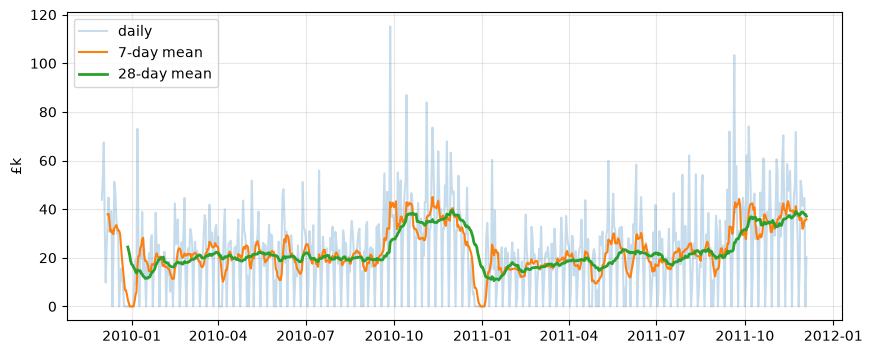

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily / 1000, alpha=.25, label="daily")
plt.plot(daily.index, daily.rolling(7).mean() / 1000, label="7-day mean")
plt.plot(daily.index, daily.rolling(28).mean() / 1000, label="28-day mean", linewidth=2)
plt.ylabel("£k"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. The weekly rhythm

Every series has its own calendar. ShopWave's is clear once you average by weekday.

In [7]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
open_days = daily[daily > 0]
by_dow = open_days.groupby(open_days.index.day_of_week).agg(["mean", "count"])
by_dow.index = [names[i] for i in by_dow.index]
(by_dow.assign(mean=lambda t: (t["mean"] / 1000).round(1))
       .rename(columns={"mean": "avg £k (open days)", "count": "days open"}))

,avg £k (open days),days open
Mon,29.2,93
Tue,31.1,103
Wed,28.7,103
Thu,36.2,102
Fri,26.0,98
Sat,9.8,1
Sun,17.9,99


Thursday is the busiest day, Sunday the quietest, and Saturday is effectively closed (one day of trading in two years). A daily model must know the day of the week; a weekly model does not need to.

## 5. Decomposition: trend + seasonality + noise

`seasonal_decompose` splits a series into three parts:

- **trend**: a centred rolling mean over one full season (52 weeks),
- **seasonal**: the average deviation from the trend for each week of the year,
- **residual**: whatever is left.

**Additive** means `observed = trend + seasonal + residual`. Use it when the seasonal swing is roughly the same size in pounds every year.

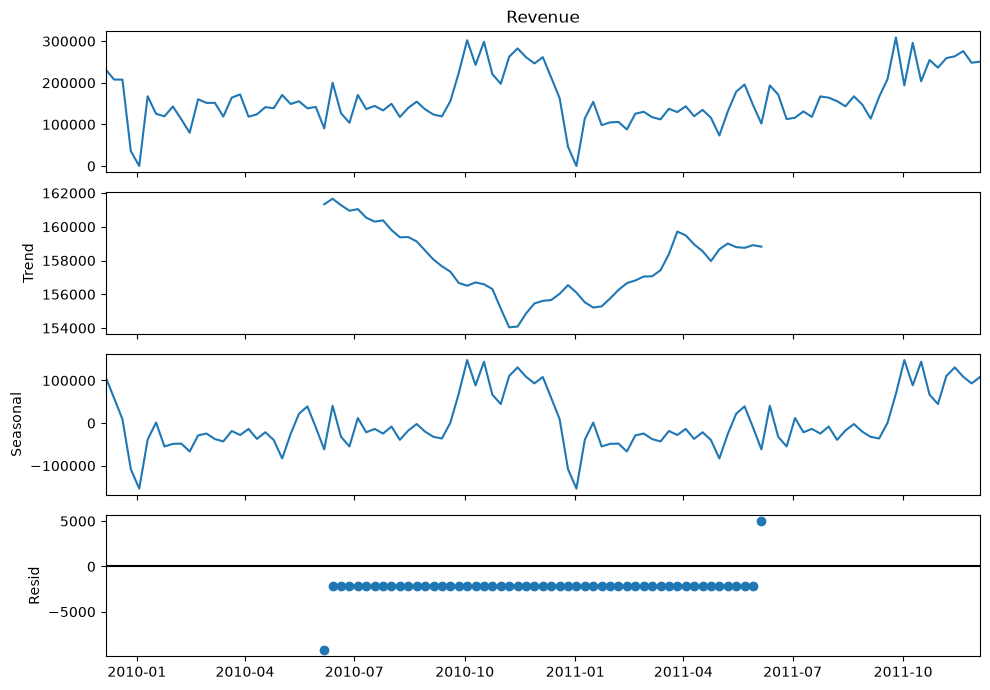

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

dec = seasonal_decompose(weekly, model="additive", period=52)
fig = dec.plot(); fig.set_size_inches(10, 7); plt.tight_layout(); plt.show()

In [9]:
one_year = dec.seasonal.iloc[:52]                      # the pattern repeats every 52 weeks
by_month = one_year.groupby(one_year.index.month).mean()
print("Average seasonal effect by month (£ per week):")
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(by_month.set_axis([months[m - 1] for m in by_month.index]).round(-3).to_string())
print(f"\nTrend range: £{dec.trend.min():,.0f} to £{dec.trend.max():,.0f} per week")

Average seasonal effect by month (£ per week):
Jan    -59000.0
Feb    -42000.0
Mar    -32000.0
Apr    -28000.0
May    -12000.0
Jun    -27000.0
Jul    -12000.0
Aug    -17000.0
Sep         0.0
Oct     98000.0
Nov    111000.0
Dec     17000.0

Trend range: £154,043 to £161,661 per week


The seasonal panel is the story: below average from January to August (about £12k–£59k a week under trend), level in September, then roughly £100k a week *above* trend in October and November, and a deep hole over Christmas and New Year. The trend barely moves (between about £154k and £162k a week), so ShopWave is not growing; it is just very seasonal.

The centred 52-week trend can only be computed for the middle of the series (26 weeks are missing at each end), which is why the trend panel is short. With two years of data that is the price of a yearly season.

**Multiplicative** means `observed = trend × seasonal × residual`: the seasonal swing is a *percentage*. It cannot be used on the weekly series, because Christmas weeks with zero revenue make the division impossible. It works on monthly data, which never hits zero.

In [10]:
try:
    seasonal_decompose(weekly, model="multiplicative", period=52)
except ValueError as e:
    print("Weekly, multiplicative:", e)

dec_m = seasonal_decompose(monthly, model="multiplicative", period=12)
print("\nMonthly seasonal factors (1.00 = an average month):")
print(dec_m.seasonal.iloc[:12].set_axis(dec_m.seasonal.index[:12].strftime("%b")).round(2).to_string())

Weekly, multiplicative: Multiplicative seasonality is not appropriate for zero and negative values

Monthly seasonal factors (1.00 = an average month):
InvoiceDate
Dec    0.85
Jan    0.73
Feb    0.66
Mar    0.88
Apr    0.69
May    0.99
Jun    0.92
Jul    0.86
Aug    0.88
Sep    1.23
Oct    1.55
Nov    1.76


Read the factors as "November sells about 1.76× an average month, February about 0.66×". This is the single most useful number for ShopWave's stock planning, and you got it from two lines of code.

## 6. Autocorrelation: does the past predict the future?

**Autocorrelation at lag k** is the correlation between the series and itself shifted by *k* steps. High autocorrelation at lag 1 means "this week looks like last week"; high at lag 52 means "this week looks like the same week last year". The ACF plot shows it for every lag; bars outside the shaded band are unlikely to be chance.

lag  1: autocorrelation 0.67
lag  2: autocorrelation 0.49
lag  4: autocorrelation 0.36
lag 52: autocorrelation 0.81


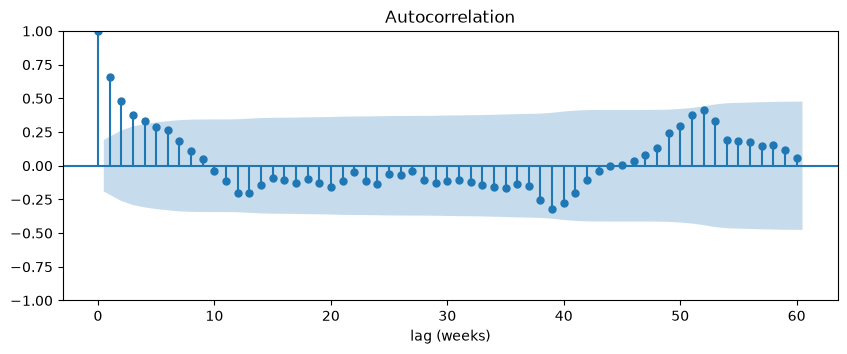

In [11]:
from statsmodels.graphics.tsaplots import plot_acf

for k in [1, 2, 4, 52]:
    print(f"lag {k:>2}: autocorrelation {weekly.autocorr(k):.2f}")
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(weekly, lags=60, ax=ax); ax.set_xlabel("lag (weeks)"); plt.show()

Last week tells you a lot (lag 1), and the same week last year tells you even more (lag 52). Every forecasting method in this module is a way of combining those two memories.

## 7. Why random splits are wrong for time

In Module 04 you shuffled rows into train and test. On a time series that leaks the future. Here is the effect: two "forecasters" that predict a test week from its neighbours.

- **Random split**: hide 20% of weeks at random, predict each from the average of the week before and the week after. Both neighbours are known, because they are in train.
- **Time split**: hide the last 20% of weeks, predict each from the last known week. This is the situation you are actually in when you forecast.

In [12]:
rng = np.random.default_rng(0)
idx = np.arange(1, len(weekly) - 1)
test_random = rng.choice(idx, size=int(0.2 * len(weekly)), replace=False)
neighbours = (weekly.values[test_random - 1] + weekly.values[test_random + 1]) / 2
mae_random = np.abs(weekly.values[test_random] - neighbours).mean()

cut = int(0.8 * len(weekly))
mae_time = np.abs(weekly.values[cut:] - weekly.values[cut - 1]).mean()
print(f"Random split, average of neighbours: MAE £{mae_random:,.0f}")
print(f"Time split, last known week:         MAE £{mae_time:,.0f}")

Random split, average of neighbours: MAE £41,766
Time split, last known week:         MAE £78,609


The random split looks far better, but only because it peeks at the following week. A model scored this way would disappoint as soon as it met the real future. **From now on, every split in this module is in time order.** Lesson 07.2 builds the honest version properly.

## Quiz answers

1. `resample` groups rows by time period (day, week, month) using a `DatetimeIndex`. It is `groupby` for time.
2. A 3-day rolling mean has no value for the first two days, because fewer than three values exist yet.
3. Trend: the long-run level. Seasonality: a pattern that repeats on a fixed calendar. Noise (residual): what is left. ShopWave's November peak is seasonality.
4. Multiplicative needs every value to be positive; the Christmas-closure weeks are zero.
5. A random split lets the model see weeks *after* each test week, so it is interpolating, not forecasting. Real forecasts only ever have the past.

**Next:** [07.2 Baselines and honest evaluation](../02-baselines-and-evaluation/)